## SVM i techniki resamplingu

Dane: zbiór pacjentów z poprzednich zajęć (612 obserwacji, zmienna wynikowa `stroke`: 1 – udar, 0 – brak udaru).

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import confusion_matrix

dane = pd.read_csv("stroke_zaj1.csv", decimal=",", sep=";")
print(dane.shape)
print(dane["stroke"].value_counts())

(612, 11)
stroke
0    403
1    209
Name: count, dtype: int64


## Przygotowanie danych

Kroki zapisane są jako funkcja, ponieważ w zadaniu 3 (symulacja) trzeba je powtórzyć dla wielu zbiorów danych.

In [4]:
def przygotuj_dane(dane, seed=42):
    X = dane.drop(columns="stroke")
    y = dane["stroke"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed
    )
    X_train, X_test = X_train.copy(), X_test.copy()

    # Zmienne liczbowe: mediana ze zbioru uczącego
    kolumny_liczbowe = X.select_dtypes(include=np.number).columns
    imputer = SimpleImputer(strategy="median").fit(X_train[kolumny_liczbowe])
    X_train[kolumny_liczbowe] = imputer.transform(X_train[kolumny_liczbowe])
    X_test[kolumny_liczbowe] = imputer.transform(X_test[kolumny_liczbowe])

    # Zmienne kategoryczne: uzupełnianie proporcjonalne (proporcje ze zbioru uczącego)
    rng = np.random.default_rng(seed)
    for kolumna in X.select_dtypes(exclude=np.number).columns:
        proporcje = X_train[kolumna].value_counts(normalize=True)
        for zbior in (X_train, X_test):
            braki = zbior[kolumna].isna()
            zbior.loc[braki, kolumna] = rng.choice(proporcje.index, size=braki.sum(), p=proporcje.values)

    # Kodowanie zmiennych kategorycznych
    for zbior in (X_train, X_test):
        zbior["gender"] = zbior["gender"].map({"Male": 1, "Female": 0})
        zbior["ever_married"] = zbior["ever_married"].map({"Yes": 1, "No": 0})
    kolumny_dummy = ["work_type", "Residence_type", "smoking_status"]
    X_train = pd.get_dummies(X_train, columns=kolumny_dummy, dtype=int)
    X_test = pd.get_dummies(X_test, columns=kolumny_dummy, dtype=int).reindex(columns=X_train.columns, fill_value=0)

    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = przygotuj_dane(dane)

print("Zbiór uczący:", X_train.shape, "| zbiór testowy:", X_test.shape)
print("Braki danych:", X_train.isna().sum().sum(), X_test.isna().sum().sum())
print("Udział klasy 1 – uczący: %.3f, testowy: %.3f" % (y_train.mean(), y_test.mean()))

Zbiór uczący: (489, 17) | zbiór testowy: (123, 17)
Braki danych: 0 0
Udział klasy 1 – uczący: 0.342, testowy: 0.341


### Funkcje pomocnicze

In [5]:
MIARY = ["dokladnosc", "czulosc", "specyficznosc"]
ETYKIETY = ["Dokładność", "Czułość", "Specyficzność"]
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def oblicz_miary(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "dokladnosc": (tp + tn) / (tn + fp + fn + tp),
        "czulosc": tp / (tp + fn),
        "specyficznosc": tn / (tn + fp),
    }


def ocen_model(model):
    return pd.DataFrame({
        "uczący": oblicz_miary(y_train, model.predict(X_train)),
        "testowy": oblicz_miary(y_test, model.predict(X_test)),
    }).T.round(3)


def macierze_pomylek(model, tytul):
    fig, osie = plt.subplots(1, 2, figsize=(9, 3.5))
    for os_, (nazwa, X_, y_) in zip(osie, [("uczący", X_train, y_train), ("testowy", X_test, y_test)]):
        sns.heatmap(confusion_matrix(y_, model.predict(X_)), annot=True, fmt="d", cmap="Blues", ax=os_,
                    xticklabels=["brak udaru", "udar"], yticklabels=["brak udaru", "udar"])
        os_.set_title(f"Zbiór {nazwa}")
        os_.set_xlabel("Przewidywana klasa")
        os_.set_ylabel("Rzeczywista klasa")
    fig.suptitle(tytul)
    plt.tight_layout()
    plt.show()

# SVM ze standaryzacją w pipeline, dopasowanie tylko do danych uczących.
def model_svm(**parametry):
    return Pipeline([("scaler", StandardScaler()), ("svm", SVC(**parametry))])


def badaj_parametr(budowa_modelu, wartosci, nazwa):
    wiersze = []
    for wartosc in wartosci:
        model = budowa_modelu(wartosc).fit(X_train, y_train)
        for zbior, X_, y_ in [("uczący", X_train, y_train), ("testowy", X_test, y_test)]:
            wiersze.append({nazwa: str(wartosc), "zbior": zbior, **oblicz_miary(y_, model.predict(X_))})
    wyniki = pd.DataFrame(wiersze)
    wyniki[nazwa] = pd.Categorical(wyniki[nazwa], categories=[str(w) for w in wartosci], ordered=True)
    return wyniki


def wykres(wyniki, nazwa, tytul):
    fig, osie = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    for os_, miara, etykieta in zip(osie, MIARY, ETYKIETY):
        for zbior, styl in [("uczący", "-"), ("testowy", "--")]:
            d = wyniki[wyniki["zbior"] == zbior]
            os_.plot(d[nazwa].astype(str), d[miara], styl, marker="o", label=zbior)
        os_.set_title(etykieta)
        os_.set_xlabel(nazwa)
        os_.grid(alpha=0.3)
    osie[0].legend()
    fig.suptitle(tytul)
    plt.tight_layout()
    plt.show()

## Zadanie 1. Algorytm SVM

### a) Jądro liniowe

In [6]:
svm_liniowy = model_svm(kernel="linear").fit(X_train, y_train)
print("Liczba wektorów nośnych (klasa 0, klasa 1):", svm_liniowy.named_steps["svm"].n_support_)
ocen_model(svm_liniowy)

Liczba wektorów nośnych (klasa 0, klasa 1): [127 126]


,dokladnosc,czulosc,specyficznosc
uczący,0.785,0.671,0.845
testowy,0.715,0.619,0.765


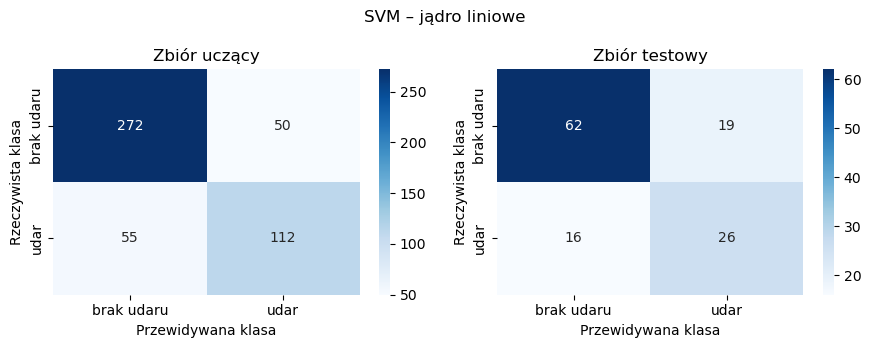

In [7]:
macierze_pomylek(svm_liniowy, "SVM – jądro liniowe")

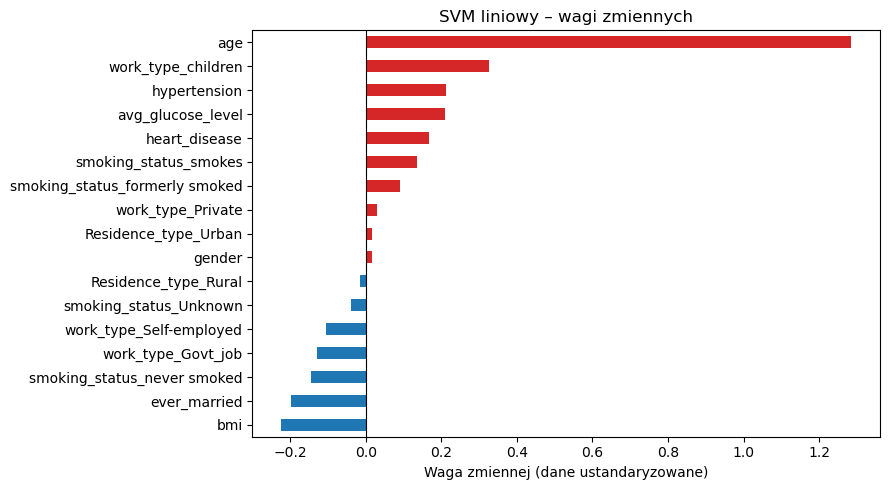

In [8]:
wagi = pd.Series(svm_liniowy.named_steps["svm"].coef_[0], index=X_train.columns).sort_values()

plt.figure(figsize=(9, 5))
wagi.plot(kind="barh", color=np.where(wagi > 0, "tab:red", "tab:blue"))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Waga zmiennej (dane ustandaryzowane)")
plt.title("SVM liniowy – wagi zmiennych")
plt.tight_layout()
plt.show()

### b) Jądro wielomianowe

In [9]:
svm_wielomianowy = model_svm(kernel="poly").fit(X_train, y_train)
print("Liczba wektorów nośnych (klasa 0, klasa 1):", svm_wielomianowy.named_steps["svm"].n_support_)
ocen_model(svm_wielomianowy)

Liczba wektorów nośnych (klasa 0, klasa 1): [169 149]


,dokladnosc,czulosc,specyficznosc
uczący,0.818,0.533,0.966
testowy,0.707,0.381,0.877


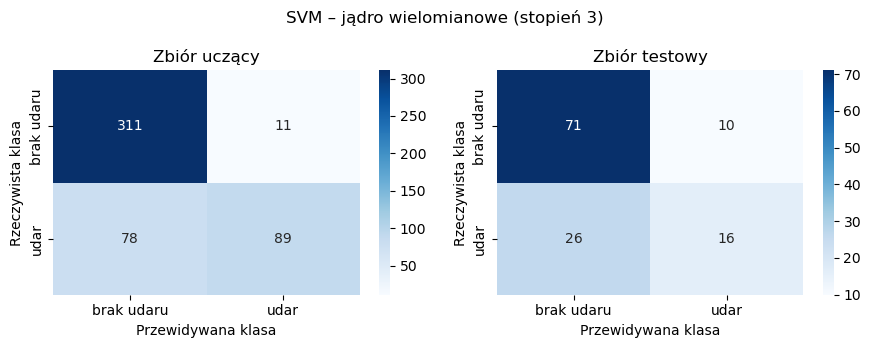

In [10]:
macierze_pomylek(svm_wielomianowy, "SVM – jądro wielomianowe (stopień 3)")

### c) Jądro radialne (RBF)

In [11]:
svm_rbf = model_svm(kernel="rbf").fit(X_train, y_train)
print("Liczba wektorów nośnych (klasa 0, klasa 1):", svm_rbf.named_steps["svm"].n_support_)
ocen_model(svm_rbf)

Liczba wektorów nośnych (klasa 0, klasa 1): [162 149]


,dokladnosc,czulosc,specyficznosc
uczący,0.847,0.731,0.907
testowy,0.724,0.595,0.790


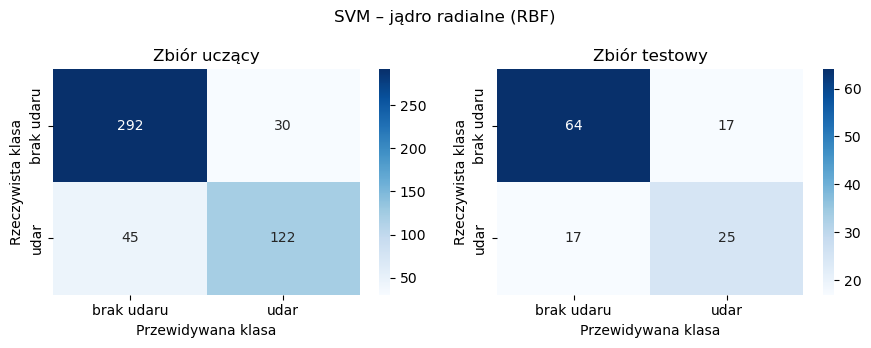

In [12]:
macierze_pomylek(svm_rbf, "SVM – jądro radialne (RBF)")

### Porównanie jąder i wybór najlepszego modelu

Najlepszy model jest wybrany na podstawie 5-krotnej walidacji krzyżowej na zbiorze uczącym (kryterium: *balanced accuracy*, czyli średnia czułości i specyficzności), a nie na podstawie zbioru testowego.

In [13]:
jadra = {"linear": svm_liniowy, "poly": svm_wielomianowy, "rbf": svm_rbf}

porownanie_jader = pd.DataFrame({
    jadro: {
        **{f"test_{m}": v for m, v in oblicz_miary(y_test, model.predict(X_test)).items()},
        "CV_balanced_accuracy": cross_val_score(model_svm(kernel=jadro), X_train, y_train,
                                                cv=kfold, scoring="balanced_accuracy").mean(),
        "wektory_nosne": model.named_steps["svm"].n_support_.sum(),
    }
    for jadro, model in jadra.items()
}).T

najlepsze_jadro = porownanie_jader["CV_balanced_accuracy"].astype(float).idxmax()
print("Najlepsze jądro wg walidacji krzyżowej:", najlepsze_jadro)
porownanie_jader.round(3)

Najlepsze jądro wg walidacji krzyżowej: linear


,test_dokladnosc,test_czulosc,test_specyficznosc,CV_balanced_accuracy,wektory_nosne
linear,0.715,0.619,0.765,0.725,253.0
poly,0.707,0.381,0.877,0.604,318.0
rbf,0.724,0.595,0.790,0.674,311.0


### d) Wpływ hiperparametrów najlepszego modelu

Dla jądra liniowego najważniejszym hiperparametrem jest `C`, czyli kara za błędną klasyfikację:
- **małe `C`**: szeroki margines, model toleruje wiele błędów na zbiorze uczącym (prostszy model, ryzyko niedouczenia),
- **duże `C`**: wąski margines, model stara się poprawnie sklasyfikować jak najwięcej obserwacji uczących (ryzyko przeuczenia).

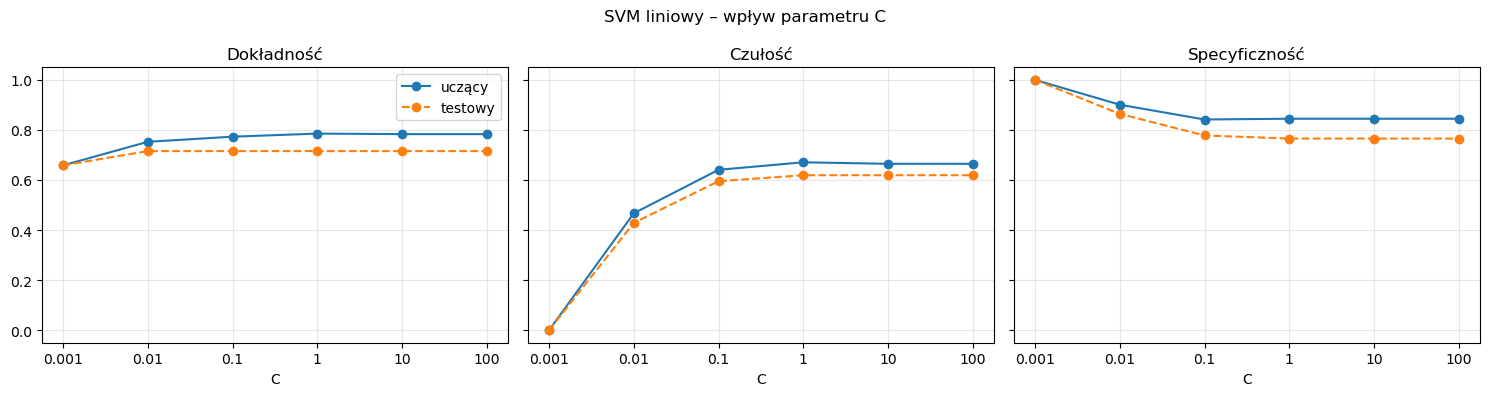

dokladnosc        czulosc        specyficznosc       
zbior    testowy uczący testowy uczący       testowy uczący
C                                                          
0.001      0.659  0.658   0.000  0.000         1.000  1.000
0.01       0.715  0.753   0.429  0.467         0.864  0.901
0.1        0.715  0.773   0.595  0.641         0.778  0.842
1          0.715  0.785   0.619  0.671         0.765  0.845
10         0.715  0.783   0.619  0.665         0.765  0.845
100        0.715  0.783   0.619  0.665         0.765  0.845

In [14]:
wartosci_C = [0.001, 0.01, 0.1, 1, 10, 100]

wyniki_C = badaj_parametr(lambda c: model_svm(kernel="linear", C=c), wartosci_C, "C")
wykres(wyniki_C, "C", "SVM liniowy – wpływ parametru C")
wyniki_C.pivot(index="C", columns="zbior", values=MIARY).round(3)

In [15]:
cv_C = pd.Series({
    str(c): cross_val_score(model_svm(kernel="linear", C=c), X_train, y_train,
                            cv=kfold, scoring="balanced_accuracy").mean()
    for c in wartosci_C
}, name="CV balanced accuracy")

najlepsze_C = float(cv_C.idxmax())
print("Najlepsze C wg walidacji krzyżowej:", najlepsze_C)
cv_C.round(3)

Najlepsze C wg walidacji krzyżowej: 10.0


0.001    0.500
0.01     0.661
0.1      0.729
1        0.725
10       0.732
100      0.732
Name: CV balanced accuracy, dtype: float64

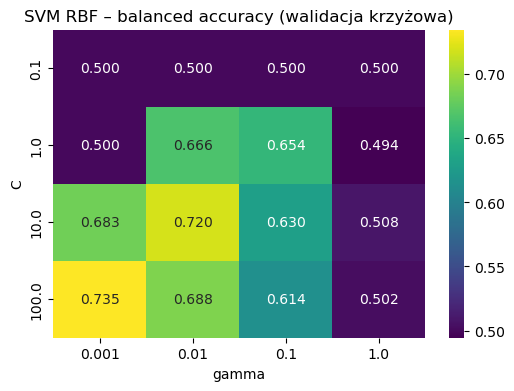

In [16]:
siatka_C = [0.1, 1, 10, 100]
siatka_gamma = [0.001, 0.01, 0.1, 1]

siatka = pd.DataFrame(
    [[cross_val_score(model_svm(kernel="rbf", C=c, gamma=g), X_train, y_train,
                      cv=kfold, scoring="balanced_accuracy").mean()
      for g in siatka_gamma] for c in siatka_C],
    index=pd.Index(siatka_C, name="C"), columns=pd.Index(siatka_gamma, name="gamma"),
)

plt.figure(figsize=(6, 4))
sns.heatmap(siatka, annot=True, fmt=".3f", cmap="viridis")
plt.title("SVM RBF – balanced accuracy (walidacja krzyżowa)")
plt.show()

### Model końcowy z zadania 1

In [17]:
svm_najlepszy = model_svm(kernel="linear", C=najlepsze_C).fit(X_train, y_train)
ocen_model(svm_najlepszy)

,dokladnosc,czulosc,specyficznosc
uczący,0.783,0.665,0.845
testowy,0.715,0.619,0.765


## Zadanie 2. Techniki resamplingu

### a) Wpływ resamplingu na wyniki modelu

In [18]:
# Zwraca indeksy klasy mniejszościowej i większościowej
def podziel_klasy(y):
    i0, i1 = np.flatnonzero(y == 0), np.flatnonzero(y == 1)
    return (i1, i0) if len(i1) < len(i0) else (i0, i1)


# Losowanie ze zwracaniem obserwacji klasy mniejszościowej, aż obie klasy będą równe
def losowy_oversampling(X, y, rng):
    mniejsza, wieksza = podziel_klasy(y)
    dodatkowe = rng.choice(mniejsza, size=len(wieksza) - len(mniejsza), replace=True)
    indeksy = np.concatenate([wieksza, mniejsza, dodatkowe])
    return X[indeksy], y[indeksy]


# Losowanie bez zwracania tylu obserwacji klasy większościowej, ile jest w klasie mniejszościowej.
def losowy_undersampling(X, y, rng):
    mniejsza, wieksza = podziel_klasy(y)
    wybrane = rng.choice(wieksza, size=len(mniejsza), replace=False)
    indeksy = np.concatenate([wybrane, mniejsza])
    return X[indeksy], y[indeksy]


# SMOTE: nowa obserwacja = punkt klasy mniejszościowej + losowa część odcinka do jednego z k najbliższych sąsiadów z tej samej klasy.
def smote(X, y, rng, k=5):
    mniejsza, wieksza = podziel_klasy(y)
    X_min = X[mniejsza]
    ile_nowych = len(wieksza) - len(mniejsza)
    k = min(k, len(X_min) - 1)
    sasiedzi = NearestNeighbors(n_neighbors=k + 1).fit(X_min).kneighbors(X_min, return_distance=False)[:, 1:]

    punkt = rng.integers(0, len(X_min), ile_nowych)                    # losowy punkt klasy mniejszościowej
    sasiad = sasiedzi[punkt, rng.integers(0, k, ile_nowych)]           # losowy z jego k sąsiadów
    lam = rng.random((ile_nowych, 1))                                  # losowa liczba z przedziału [0, 1)
    nowe = X_min[punkt] + lam * (X_min[sasiad] - X_min[punkt])

    klasa_mniejsza = y[mniejsza[0]]
    return np.vstack([X, nowe]), np.concatenate([y, np.full(ile_nowych, klasa_mniejsza)])


METODY = {
    "brak": None,
    "oversampling": losowy_oversampling,
    "undersampling": losowy_undersampling,
    "SMOTE": smote,
}

In [19]:
def dopasuj(X_tr, y_tr, metoda, rng, wagi_klas=None):
    skaler = StandardScaler().fit(X_tr)
    X_s, y_s = skaler.transform(X_tr), np.asarray(y_tr)
    if METODY.get(metoda) is not None:
        X_s, y_s = METODY[metoda](X_s, y_s, rng)
    svm = SVC(kernel="linear", C=najlepsze_C, class_weight=wagi_klas).fit(X_s, y_s)
    return skaler, svm, y_s


# Liczebność klas po resamplingu (zbiór uczący)
liczebnosci = {}
for metoda in METODY:
    _, _, y_po = dopasuj(X_train, y_train, metoda, np.random.default_rng(42))
    liczebnosci[metoda] = np.bincount(y_po)
pd.DataFrame(liczebnosci, index=["klasa 0", "klasa 1"]).T

,klasa 0,klasa 1
brak,322,167
oversampling,322,322
undersampling,167,167
SMOTE,322,322


In [20]:
warianty = [(m, m, None) for m in METODY] + [("wagi klas", "brak", "balanced")]

wyniki_test, wyniki_cv = {}, {}
for nazwa, metoda, wagi_klas in warianty:
    # Zbiór testowy
    skaler, svm, _ = dopasuj(X_train, y_train, metoda, np.random.default_rng(42), wagi_klas)
    wyniki_test[nazwa] = oblicz_miary(y_test, svm.predict(skaler.transform(X_test)))

    # Walidacja krzyżowa: resampling osobno w każdym podziale, tylko na części uczącej
    miary_cv = []
    for nr, (i_ucz, i_wal) in enumerate(kfold.split(X_train, y_train)):
        skaler, svm, _ = dopasuj(X_train.iloc[i_ucz], y_train.iloc[i_ucz], metoda,
                                 np.random.default_rng(nr), wagi_klas)
        miary_cv.append(oblicz_miary(y_train.iloc[i_wal], svm.predict(skaler.transform(X_train.iloc[i_wal]))))
    wyniki_cv[nazwa] = pd.DataFrame(miary_cv).mean()

wyniki_test = pd.DataFrame(wyniki_test).T
wyniki_cv = pd.DataFrame(wyniki_cv).T

print("Zbiór testowy:")
print(wyniki_test.round(3))
print("\nŚrednia z 5-krotnej walidacji krzyżowej:")
print(wyniki_cv.round(3))

Zbiór testowy:
               dokladnosc  czulosc  specyficznosc
brak                0.715    0.619          0.765
oversampling        0.683    0.714          0.667
undersampling       0.675    0.714          0.654
SMOTE               0.691    0.690          0.691
wagi klas           0.715    0.738          0.704

Średnia z 5-krotnej walidacji krzyżowej:
               dokladnosc  czulosc  specyficznosc
brak                0.767    0.623          0.842
oversampling        0.751    0.760          0.745
undersampling       0.759    0.796          0.739
SMOTE               0.757    0.760          0.755
wagi klas           0.757    0.771          0.748


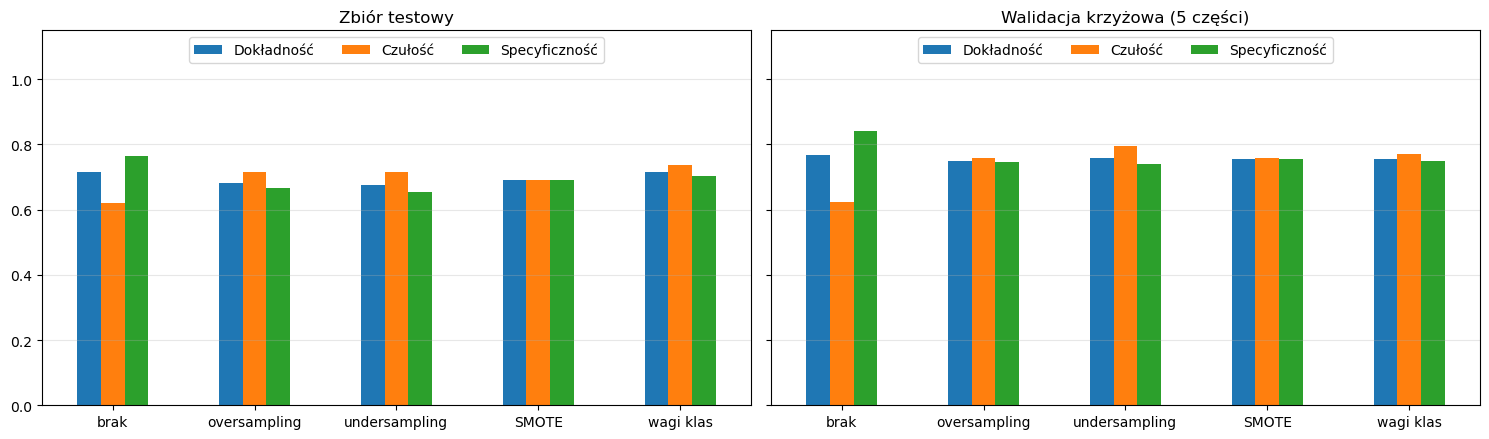

In [21]:
fig, osie = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for os_, (tytul, df) in zip(osie, [("Zbiór testowy", wyniki_test), ("Walidacja krzyżowa (5 części)", wyniki_cv)]):
    df.set_axis(ETYKIETY, axis=1).plot(kind="bar", ax=os_, rot=0)
    os_.set_title(tytul)
    os_.set_ylim(0, 1.15)
    os_.legend(loc="upper center", ncol=3)
    os_.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### b) Opis technik resamplingu

## Zadanie 3. Symulacja

Aby uzyskać zbiory o różnym stopniu niezbalansowania, pozostawione zostją wszystkie 403 obserwacje klasy 0 i losowana jest część obserwacji klasy 1, tak aby udział klasy pozytywnej wynosił 5%, 10%, 20% lub 34% (pełny zbiór).

Dla każdego udziału losowanie powtórzone jest 50 razy, ponieważ przy małym udziale w zbiorze testowym znajduje się tylko kilka przypadków udaru i wynik pojedynczego losowania byłby bardzo niestabilny. W każdym powtórzeniu następuje:
1. losowanie obserwacje klasy 1,
2. przygotowanie danych (podział, uzupełnienie braków, kodowanie) funkcją `przygotuj_dane`,
3. budowa SVM liniowego bez resamplingu i z każdą techniką resamplingu,
4. obliczenie miar na zbiorze testowym.

Na końcu uśrednienie wyników z 50 powtórzeń.

In [22]:
udzialy = [0.05, 0.10, 0.20, 0.34]
liczba_powtorzen = 50

negatywne = dane[dane["stroke"] == 0]
pozytywne = dane[dane["stroke"] == 1]

wyniki_symulacji = []
for udzial in udzialy:
    liczba_pozytywnych = round(udzial / (1 - udzial) * len(negatywne))
    for powtorzenie in range(liczba_powtorzen):
        probka = pd.concat([negatywne, pozytywne.sample(liczba_pozytywnych, random_state=powtorzenie)])
        X_tr, X_te, y_tr, y_te = przygotuj_dane(probka, seed=powtorzenie)
        for metoda in METODY:
            skaler, svm, _ = dopasuj(X_tr, y_tr, metoda, np.random.default_rng(powtorzenie))
            wyniki_symulacji.append({
                "udzial_klasy_1": udzial, "metoda": metoda, "powtorzenie": powtorzenie,
                "liczba_1_w_tescie": int(y_te.sum()),
                **oblicz_miary(y_te, svm.predict(skaler.transform(X_te))),
            })

wyniki_symulacji = pd.DataFrame(wyniki_symulacji)
print("Średnia liczba przypadków udaru w zbiorze testowym:")
print(wyniki_symulacji.groupby("udzial_klasy_1")["liczba_1_w_tescie"].mean())

Średnia liczba przypadków udaru w zbiorze testowym:
udzial_klasy_1
0.05     4.0
0.10     9.0
0.20    20.0
0.34    42.0
Name: liczba_1_w_tescie, dtype: float64


In [23]:
srednie = wyniki_symulacji.groupby(["udzial_klasy_1", "metoda"])[MIARY].mean()
srednie.unstack("metoda").reindex(columns=list(METODY), level="metoda").round(3)

dokladnosc                                   czulosc  \
metoda               brak oversampling undersampling  SMOTE    brak   
udzial_klasy_1                                                        
0.05                0.952        0.772         0.660  0.766   0.000   
0.10                0.895        0.737         0.696  0.741   0.002   
0.20                0.798        0.740         0.729  0.743   0.258   
0.34                0.760        0.749         0.747  0.745   0.638   

                                                 specyficznosc               \
metoda         oversampling undersampling  SMOTE          brak oversampling   
udzial_klasy_1                                                                
0.05                  0.550         0.620  0.505         1.000        0.783   
0.10                  0.716         0.702  0.711         0.994        0.740   
0.20                  0.732         0.740  0.714         0.931        0.742   
0.34                  0.762         0.775  0.769         0.823        0.742   

                                     
metoda         undersampling  SMOTE  
udzial_klasy_1                       
0.05                   0.662  0.779  
0.10                   0.696  0.744  
0.20                   0.726  0.750  
0.34                   0.732  0.733

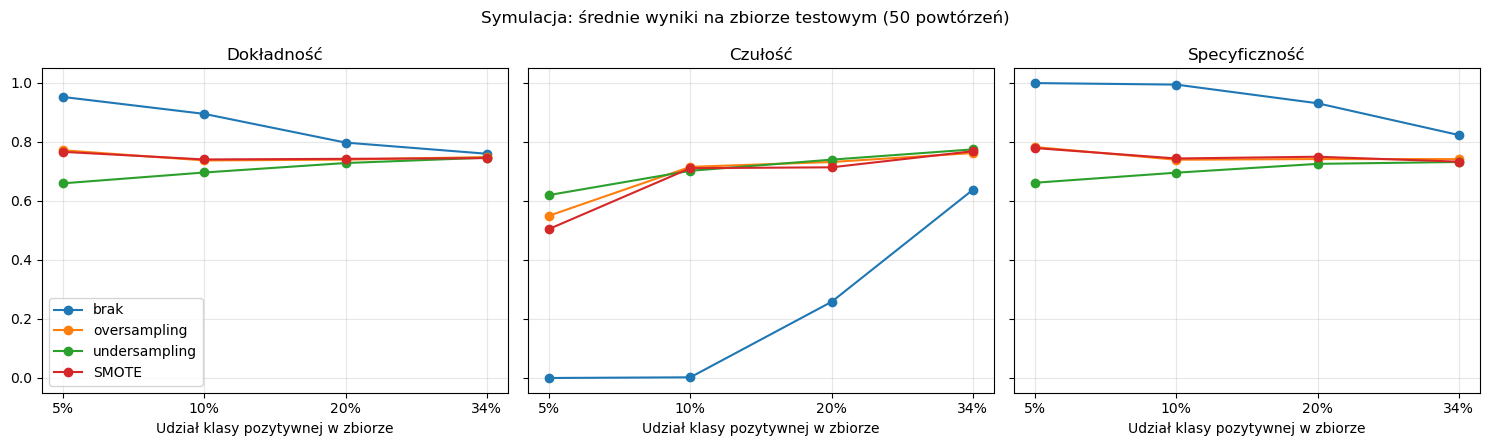

In [24]:
fig, osie = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for os_, miara, etykieta in zip(osie, MIARY, ETYKIETY):
    for metoda in METODY:
        d = srednie.xs(metoda, level="metoda")[miara]
        os_.plot([f"{u:.0%}" for u in d.index], d.values, marker="o", label=metoda)
    os_.set_title(etykieta)
    os_.set_xlabel("Udział klasy pozytywnej w zbiorze")
    os_.grid(alpha=0.3)
osie[0].legend()
fig.suptitle(f"Symulacja: średnie wyniki na zbiorze testowym ({liczba_powtorzen} powtórzeń)")
plt.tight_layout()
plt.show()

In [25]:
# Zmienność wyników: odchylenie standardowe czułości między powtórzeniami
wyniki_symulacji.groupby(["udzial_klasy_1", "metoda"])["czulosc"].std().unstack("metoda")[list(METODY)].round(3)

metoda,brak,oversampling,undersampling,SMOTE
udzial_klasy_1,,,,
0.05,0.000,0.281,0.254,0.274
0.10,0.016,0.147,0.158,0.157
0.20,0.119,0.091,0.099,0.098
0.34,0.060,0.052,0.061,0.055


## Podsumowanie